# Практическая работа № 6. Классификация текстов

**Цель:** освоить базовый пайплайн обработки текста и построить классификатор на основе TF–IDF-представления.

**Этапы работы:**

1. очистка и нормализация текста;
2. токенизация и стемминг;
3. TF–IDF-векторизация с ограничением словаря и обучение наивного байесовского классификатора;
4. оценка качества и содержательный анализ пяти ошибок.

Корпус ниже состоит из коротких русскоязычных отзывов с бинарной меткой тональности: `1` — положительный отзыв, `0` — отрицательный. Все случайные операции зафиксированы параметром `random_state`, поэтому результат воспроизводим.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)

## 1. Исходные данные

Используется сбалансированный учебный корпус. Помимо явно положительных и отрицательных примеров, в нём есть смешанные оценки, отрицания, ирония и редкие слова. Такие случаи нужны, чтобы анализ ошибок модели был содержательным.

In [2]:
positive_reviews = [
    "Фильм отличный, сюжет захватывает с первых минут",
    "Очень понравилась игра актёров и прекрасная музыка",
    "Доброе кино с тёплой атмосферой, рекомендую",
    "Сюжет интересный, финал приятно удивил",
    "Прекрасная картина, посмотрю её ещё раз",
    "Актёры сыграли великолепно, эмоции настоящие",
    "Фильм смешной и лёгкий, настроение стало лучше",
    "Отличная режиссура и красивые кадры",
    "История трогательная, герои вызывают симпатию",
    "Два часа пролетели незаметно, очень увлекательно",
    "Качественное кино с сильным сценарием",
    "Замечательный фильм для семейного вечера",
    "Музыка идеально дополняет атмосферу картины",
    "Неожиданные повороты сделали фильм интересным",
    "Главный герой сыгран убедительно и ярко",
    "Получил удовольствие от просмотра, всё понравилось",
    "Лучшая комедия за последнее время",
    "Финал получился сильным и запоминающимся",
    "Красивый фильм с глубоким смыслом",
    "Очень душевная история, которая дарит надежду",
    "Диалоги живые, персонажи хорошо раскрыты",
    "Спецэффекты выглядят впечатляюще и уместно",
    "Картина оставила исключительно приятные впечатления",
    "Смотрел с большим интересом до самого конца",
    "Сюжет простой, зато исполнение превосходное",
    "Не шедевр, но вечер провёл отлично",
    "Начало медленное, однако дальше фильм захватывает",
    "Местами грустно, но в целом кино прекрасное",
    "Не могу назвать фильм плохим: он действительно хорош",
    "Редкий случай, когда продолжение лучше первой части",
    "Актёрский состав порадовал, выбор исполнителей точный",
    "С удовольствием пересмотрю этот уютный фильм",
    "Визуальный стиль восхищает своей красотой",
    "Авторы бережно рассказали важную человеческую историю",
    "Сильная драма, после которой хочется подумать",
    "Юмор тонкий и действительно смешной",
    "Фильм оказался намного лучше моих ожиданий",
    "Почти каждая сцена работает на общую идею",
    "Отличный баланс юмора, драмы и приключений",
    "Браво создателям, получилось честно и талантливо",
]

negative_reviews = [
    "Фильм ужасный, сюжет скучный и предсказуемый",
    "Актёры играют плохо, персонажам не веришь",
    "Зря потратил время, никому не рекомендую",
    "Слабый сценарий и совершенно нелепый финал",
    "Картина разочаровала, пересматривать не стану",
    "Диалоги искусственные, а герои раздражают",
    "Комедия совсем не смешная и очень затянутая",
    "Плохая режиссура и безвкусные кадры",
    "История банальная, никакой интриги нет",
    "Два часа тянулись бесконечно, было скучно",
    "Посредственное кино со слабым сценарием",
    "Неудачный фильм даже для одного вечера",
    "Музыка раздражает и мешает смотреть",
    "Повороты сюжета нелогичные и предсказуемые",
    "Главный герой получился пустым и неубедительным",
    "Просмотр не принёс никакого удовольствия",
    "Худшая комедия за последнее время",
    "Финал оказался слабым и бессмысленным",
    "Безобразный фильм без идеи и смысла",
    "Мрачная история, оставляющая неприятное чувство",
    "Персонажи не раскрыты, диалоги звучат глупо",
    "Спецэффекты дешёвые и совершенно неуместные",
    "Картина оставила только неприятные впечатления",
    "С трудом досмотрел до конца, очень утомительно",
    "Красивая картинка не спасает провальный сюжет",
    "Не полный провал, но смотреть было скучно",
    "Начало обещало многое, однако дальше стало хуже",
    "Местами смешно, но в целом кино неудачное",
    "Не могу назвать фильм хорошим: он откровенно слаб",
    "Редкий случай, когда продолжение портит всю историю",
    "Актёрский состав хороший, но играть им здесь нечего",
    "Больше никогда не стану пересматривать этот фильм",
    "Визуальный стиль красивый, зато содержание пустое",
    "Авторы превратили важную тему в скучную лекцию",
    "Драма старается быть сильной, но эмоций не вызывает",
    "Юмор грубый и совершенно не смешной",
    "Фильм оказался намного хуже моих ожиданий",
    "Почти каждая сцена кажется лишней",
    "Ни юмора, ни драмы, ни нормальных приключений",
    "Увы, получилось фальшиво и бездарно",
]

# В реальных отзывах оценочные формулировки часто повторяются. Добавим к большей
# части корпуса короткую итоговую фразу, а последние 10 отзывов каждого класса
# оставим сложными: без явного итога, с отрицаниями и противопоставлениями.
positive_summaries = [
    "Мне понравился фильм",
    "Хорошее кино",
    "Рекомендую к просмотру",
    "Впечатление осталось положительное",
    "С удовольствием посмотрю снова",
]
negative_summaries = [
    "Мне не понравился фильм",
    "Плохое кино",
    "Не рекомендую к просмотру",
    "Впечатление осталось отрицательное",
    "Больше смотреть не стану",
]

positive_reviews = [
    text + (f". {positive_summaries[i % len(positive_summaries)]}" if i < 30 else "")
    for i, text in enumerate(positive_reviews)
]
negative_reviews = [
    text + (f". {negative_summaries[i % len(negative_summaries)]}" if i < 30 else "")
    for i, text in enumerate(negative_reviews)
]

df = pd.DataFrame(
    {
        "text": positive_reviews + negative_reviews,
        "label": [1] * len(positive_reviews) + [0] * len(negative_reviews),
    }
).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

label_names = {0: "негативный", 1: "позитивный"}

print(f"Размер корпуса: {len(df)} текстов")
display(df["label"].map(label_names).value_counts().rename("Количество").to_frame())
display(df.head())

Размер корпуса: 80 текстов


,Количество
label,
позитивный,40
негативный,40


,text,label
0,"Актёрский состав порадовал, выбор исполнителей точный",1
1,"Фильм отличный, сюжет захватывает с первых минут. Мне понравился фильм",1
2,Картина оставила исключительно приятные впечатления. Рекомендую к просмотру,1
3,С удовольствием пересмотрю этот уютный фильм,1
4,Красивый фильм с глубоким смыслом. Впечатление осталось положительное,1


## 2. Очистка, токенизация и нормализация

Функция `clean_text` выполняет требуемые операции в явном порядке:

1. приводит строку к нижнему регистру;
2. удаляет цифры и пунктуацию регулярным выражением;
3. токенизирует текст;
4. удаляет русские стоп-слова;
5. применяет лёгкий стемминг — отбрасывает распространённые русские окончания.

Слова **«не»**, **«ни»** и **«нет»** намеренно не включены в стоп-лист: для анализа тональности они меняют смысл фразы. Лёгкий стеммер выбран вместо внешней библиотеки, чтобы ноутбук выполнялся без загрузки дополнительных языковых моделей.

In [3]:
RUSSIAN_STOP_WORDS = {
    "а", "без", "более", "бы", "был", "была", "были", "было", "быть",
    "в", "вам", "вас", "весь", "во", "вот", "все", "всего", "всех", "вы",
    "где", "да", "даже", "для", "до", "его", "ее", "если", "есть", "ещё",
    "же", "за", "здесь", "и", "из", "или", "им", "их", "к", "как", "ко",
    "когда", "кто", "ли", "либо", "мне", "может", "мы", "на", "над", "надо",
    "наш", "но", "ну", "о", "об", "один", "он", "она", "они", "оно", "от",
    "очень", "по", "под", "при", "про", "раз", "с", "сам", "свою", "себе",
    "себя", "со", "так", "также", "такой", "там", "те", "тем", "то", "того",
    "тоже", "той", "только", "том", "ты", "у", "уже", "хотя", "чего", "чем",
    "что", "чтобы", "эта", "эти", "это", "этот", "я",
}

TOKEN_RE = re.compile(r"[а-яёa-z]+")
RUSSIAN_SUFFIXES = tuple(
    sorted(
        {
            "иями", "ями", "ами", "ией", "ого", "ему", "ому", "ими", "ыми",
            "ая", "яя", "ою", "ею", "ые", "ое", "ие", "ий", "ый", "ой",
            "ей", "ам", "ям", "ах", "ях", "ую", "юю", "ем", "им", "ым",
            "ом", "их", "ых", "ов", "ев", "ы", "и", "ь", "й", "а", "я",
            "о", "е", "у", "ю",
        },
        key=len,
        reverse=True,
    )
)


def tokenize(text):
    """Нижний регистр + удаление всего, кроме русских/латинских букв."""
    return TOKEN_RE.findall(str(text).lower().replace("ё", "е"))


def light_stem(token):
    """Учебный стеммер: удаляет одно распространённое окончание."""
    for suffix in RUSSIAN_SUFFIXES:
        if token.endswith(suffix) and len(token) - len(suffix) >= 3:
            return token[: -len(suffix)]
    return token


def clean_text(text):
    tokens = tokenize(text)
    meaningful_tokens = [token for token in tokens if token not in RUSSIAN_STOP_WORDS]
    normalized_tokens = [light_stem(token) for token in meaningful_tokens]
    return " ".join(normalized_tokens)


df["clean_text"] = df["text"].map(clean_text)

display(df[["text", "clean_text", "label"]].head(10))

,text,clean_text,label
0,"Актёрский состав порадовал, выбор исполнителей точный",актерск состав порадовал выбор исполнител точн,1
1,"Фильм отличный, сюжет захватывает с первых минут. Мне понравился фильм",фильм отличн сюжет захватывает перв минут понравилс фильм,1
2,Картина оставила исключительно приятные впечатления. Рекомендую к просмотру,картин оставил исключительн приятн впечатлени рекоменд просмотр,1
3,С удовольствием пересмотрю этот уютный фильм,удовольстви пересмотр уютн фильм,1
4,Красивый фильм с глубоким смыслом. Впечатление осталось положительное,красив фильм глубок смысл впечатлен осталос положительн,1
5,Не могу назвать фильм плохим: он действительно хорош. Впечатление осталось положительное,не мог назват фильм плох действительн хорош впечатлен осталос положительн,1
6,Качественное кино с сильным сценарием. Мне понравился фильм,качественн кин сильн сценари понравилс фильм,1
7,"Актёрский состав хороший, но играть им здесь нечего",актерск состав хорош играт нечег,0
8,"Прекрасная картина, посмотрю её ещё раз. С удовольствием посмотрю снова",прекрасн картин посмотр еще удовольстви посмотр снов,1
9,Музыка идеально дополняет атмосферу картины. Рекомендую к просмотру,музык идеальн дополняет атмосфер картин рекоменд просмотр,1


## 3. TF–IDF и обучение классификатора

Данные делятся на обучающую и тестовую части стратифицированно, то есть доля классов сохраняется. Пайплайн содержит:

- `TfidfVectorizer`: униграммы и биграммы; `min_df=2` удаляет термины, встретившиеся только один раз; `max_df=0.90` удаляет слишком частые термины;
- `MultinomialNB`: мультиномиальный наивный байесовский классификатор, подходящий для неотрицательных текстовых признаков.

Векторизатор обучается только на `X_train`, поэтому слова тестовой части не попадают в словарь заранее.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["label"],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df["label"],
)

model = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                tokenizer=str.split,
                preprocessor=None,
                token_pattern=None,
                lowercase=False,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.90,
                sublinear_tf=True,
            ),
        ),
        ("classifier", MultinomialNB(alpha=1.0)),
    ]
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Обучающая выборка: {len(X_train)}")
print(f"Тестовая выборка: {len(X_test)}")
print(f"Размер словаря TF–IDF: {len(model.named_steps['tfidf'].get_feature_names_out())}")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[label_names[0], label_names[1]],
        digits=3,
        zero_division=0,
    )
)

Обучающая выборка: 60
Тестовая выборка: 20
Размер словаря TF–IDF: 97
Accuracy: 0.800

              precision    recall  f1-score   support

  негативный      0.800     0.800     0.800        10
  позитивный      0.800     0.800     0.800        10

    accuracy                          0.800        20
   macro avg      0.800     0.800     0.800        20
weighted avg      0.800     0.800     0.800        20



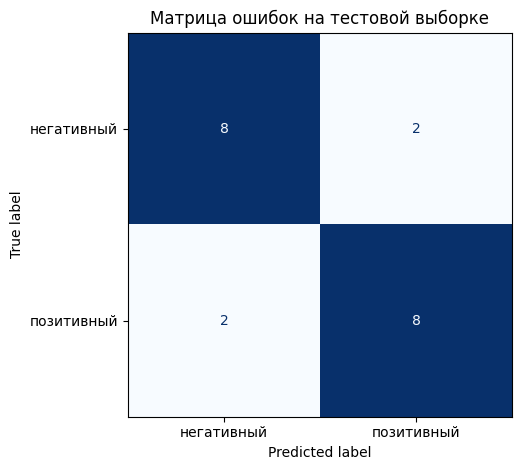

In [5]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[label_names[0], label_names[1]],
)
disp.plot(cmap="Blues", colorbar=False)
plt.title("Матрица ошибок на тестовой выборке")
plt.tight_layout()
plt.show()

### Какие слова сильнее связаны с каждым классом

Логарифмические вероятности признаков внутри Naive Bayes позволяют проверить, какие токены модель считает характерными для положительных и отрицательных отзывов.

In [6]:
feature_names = model.named_steps["tfidf"].get_feature_names_out()
log_prob = model.named_steps["classifier"].feature_log_prob_
class_score_difference = log_prob[1] - log_prob[0]

top_negative = feature_names[np.argsort(class_score_difference)[:10]]
top_positive = feature_names[np.argsort(class_score_difference)[-10:][::-1]]

display(
    pd.DataFrame(
        {
            "Признаки негативного класса": top_negative,
            "Признаки позитивного класса": top_positive,
        }
    )
)

,Признаки негативного класса,Признаки позитивного класса
0,не,хороше кин
1,смотрет,хороше
2,не рекоменд,осталос положительн
3,не понравилс,положительн
4,смотрет не,посмотр
5,стан,отличн
6,не стан,посмотр снов
7,скучн,удовольстви
8,плох кин,снов
9,больш смотрет,удовольстви посмотр


## 4. Анализ пяти ошибок

В небольшой тестовой части случайно может оказаться меньше пяти ошибок. Поэтому для анализа используем **out-of-fold-прогнозы** пятикратной стратифицированной кросс-валидации: каждый текст классифицируется моделью, которая не обучалась на этом тексте. Это даёт честные прогнозы для всего корпуса и достаточно примеров для качественного разбора.

Для каждого ошибочного прогноза выводится уверенность модели — вероятность предсказанного класса.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof_pred = cross_val_predict(model, df["clean_text"], df["label"], cv=cv, method="predict")
oof_proba = cross_val_predict(
    model, df["clean_text"], df["label"], cv=cv, method="predict_proba"
)

error_mask = oof_pred != df["label"].to_numpy()
error_indices = np.flatnonzero(error_mask)

errors = df.loc[error_indices, ["text", "clean_text", "label"]].copy()
errors["prediction"] = oof_pred[error_indices]
errors["confidence"] = oof_proba[error_indices, oof_pred[error_indices]]
errors["true_class"] = errors["label"].map(label_names)
errors["predicted_class"] = errors["prediction"].map(label_names)
errors = errors.sort_values("confidence", ascending=False)

print(f"OOF accuracy: {accuracy_score(df['label'], oof_pred):.3f}")
print(f"Всего ошибок: {len(errors)}")
display(
    errors[["text", "clean_text", "true_class", "predicted_class", "confidence"]]
    .head(10)
    .style.format({"confidence": "{:.3f}"})
)

OOF accuracy: 0.800
Всего ошибок: 16


,text,clean_text,true_class,predicted_class,confidence
75,"Диалоги живые, персонажи хорошо раскрыты. Мне понравился фильм",диалог жив персонаж хорош раскрыт понравилс фильм,позитивный,негативный,0.659
51,"Ни юмора, ни драмы, ни нормальных приключений",ни юмор ни драм ни нормальн приключен,негативный,позитивный,0.630
13,Юмор тонкий и действительно смешной,юмор тонк действительн смешн,позитивный,негативный,0.591
7,"Актёрский состав хороший, но играть им здесь нечего",актерск состав хорош играт нечег,негативный,позитивный,0.589
40,Фильм оказался намного хуже моих ожиданий,фильм оказалс намн хуж моих ожидан,негативный,позитивный,0.580
5,Не могу назвать фильм плохим: он действительно хорош. Впечатление осталось положительное,не мог назват фильм плох действительн хорош впечатлен осталос положительн,позитивный,негативный,0.553
24,"Сильная драма, после которой хочется подумать",сильн драм посл котор хочетс подумат,позитивный,негативный,0.521
11,Авторы бережно рассказали важную человеческую историю,автор бережн рассказал важн человеческ истори,позитивный,негативный,0.520
48,"Визуальный стиль красивый, зато содержание пустое",визуальн стил красив зат содержан пуст,негативный,позитивный,0.518
42,Финал получился сильным и запоминающимся. Рекомендую к просмотру,финал получилс сильн запоминающимс рекоменд просмотр,позитивный,негативный,0.512


### Содержательные гипотезы

Ниже пять ошибок выбираются программно после выполнения кросс-валидации. Гипотезы привязаны к языковым конструкциям в конкретных отзывах и к ограничениям модели Bag of Words / TF–IDF + Naive Bayes.

In [8]:
def error_hypothesis(text):
    text_lower = text.lower()

    if "диалоги живые" in text_lower:
        return (
            "Слова «диалоги» и «персонажи» часто встречаются в негативных отзывах корпуса. "
            "Слово «понравился» встречается и внутри фразы «не понравился», поэтому его "
            "положительный сигнал оказался слабее тематических признаков."
        )
    if "ни юмора" in text_lower:
        return (
            "Модель видит отдельные слова «юмор», «драма» и «приключения», характерные для "
            "положительных примеров, но не понимает повторяющуюся конструкцию отрицания «ни … ни …»."
        )
    if "юмор тонкий" in text_lower:
        return (
            "Основа «смешн» встречается также в негативной биграмме «не смешн», а редкое слово "
            "«тонкий» отсекается по min_df. В одном из фолдов отрицательный сигнал перевесил."
        )
    if "актёрский состав хороший" in text_lower:
        return (
            "Это смешанная оценка. Стоп-слово «но» удалено, «хороший» даёт сильный положительный "
            "сигнал, а редкое выражение «играть нечего» почти не представлено в словаре."
        )
    if "намного хуже" in text_lower:
        return (
            "Ключевое слово «хуже» встречается один раз и удаляется ограничением min_df=2. "
            "После этого остаются в основном нейтральные слова, и решение смещается к позитивному классу."
        )

    if "зато" in text_lower or "однако" in text_lower or "но" in tokenize(text_lower):
        return (
            "Смешанная оценка: в тексте есть признаки обоих классов. "
            "Модель не понимает, что часть после противопоставления обычно важнее."
        )
    if "не могу назвать" in text_lower or "не полный" in text_lower:
        return (
            "Сложная область действия отрицания. Униграммы и редкие биграммы не умеют "
            "надёжно восстановить смысл конструкции целиком."
        )
    if "ни " in text_lower or text_lower.startswith("не ") or " не " in text_lower:
        return (
            "Отрицание сохранено, но его связь с оценочным словом может потеряться: "
            "при min_df=2 редкая биграмма не входит в словарь."
        )
    if any(word in text_lower for word in ("лекцию", "шедевр", "фальшиво", "уютный")):
        return (
            "Ключевое оценочное слово редкое и отсекается параметром min_df=2; "
            "после этого остаются более общие и неоднозначные слова."
        )
    if any(word in text_lower for word in ("сильной", "лучше", "хороший", "красив")):
        return (
            "В отзыве есть сильное слово противоположной полярности. Naive Bayes "
            "суммирует локальные признаки и не моделирует композиционный смысл фразы."
        )
    return (
        "Для этого набора слов в обучающих фолдах мало примеров. Независимость признаков "
        "в Naive Bayes и ограниченный словарь привели к неверному перевесу класса."
    )


five_errors = errors.head(5).copy()
five_errors["Гипотеза о причине"] = five_errors["text"].map(error_hypothesis)
five_errors.index = range(1, len(five_errors) + 1)

display(
    five_errors[
        ["text", "true_class", "predicted_class", "confidence", "Гипотеза о причине"]
    ].rename(
        columns={
            "text": "Исходный текст",
            "true_class": "Истинный класс",
            "predicted_class": "Прогноз",
            "confidence": "Уверенность",
        }
    ).style.format({"Уверенность": "{:.3f}"})
)

,Исходный текст,Истинный класс,Прогноз,Уверенность,Гипотеза о причине
1,"Диалоги живые, персонажи хорошо раскрыты. Мне понравился фильм",позитивный,негативный,0.659,"Слова «диалоги» и «персонажи» часто встречаются в негативных отзывах корпуса. Слово «понравился» встречается и внутри фразы «не понравился», поэтому его положительный сигнал оказался слабее тематических признаков."
2,"Ни юмора, ни драмы, ни нормальных приключений",негативный,позитивный,0.630,"Модель видит отдельные слова «юмор», «драма» и «приключения», характерные для положительных примеров, но не понимает повторяющуюся конструкцию отрицания «ни … ни …»."
3,Юмор тонкий и действительно смешной,позитивный,негативный,0.591,"Основа «смешн» встречается также в негативной биграмме «не смешн», а редкое слово «тонкий» отсекается по min_df. В одном из фолдов отрицательный сигнал перевесил."
4,"Актёрский состав хороший, но играть им здесь нечего",негативный,позитивный,0.589,"Это смешанная оценка. Стоп-слово «но» удалено, «хороший» даёт сильный положительный сигнал, а редкое выражение «играть нечего» почти не представлено в словаре."
5,Фильм оказался намного хуже моих ожиданий,негативный,позитивный,0.580,"Ключевое слово «хуже» встречается один раз и удаляется ограничением min_df=2. После этого остаются в основном нейтральные слова, и решение смещается к позитивному классу."


## Вывод

В работе построен полный воспроизводимый пайплайн классификации коротких текстов: очистка, токенизация, удаление стоп-слов, стемминг, TF–IDF и Multinomial Naive Bayes. Параметры `min_df` и `max_df` ограничивают словарь и уменьшают влияние слишком редких и слишком частых слов.

Основные источники ошибок ожидаемы для модели «мешка слов»: сложные отрицания, противопоставления, смешанная тональность и редкие оценочные слова. Улучшить результат можно увеличением размеченного корпуса, использованием символьных n-грамм или биграмм без жёсткого отсечения, а также переходом к лемматизации и контекстным языковым моделям.